# 02 Models: forecasting and drop warning
Runs features, baselines, LightGBM, the tiny TCN and the zero-shot foundation models, then evaluates on held-out test jobs. Set `RETRAIN = False` to only display the cached results written by `python -m src.run_all` (full retraining takes about 25 minutes on a laptop).

In [1]:
import os, sys, warnings
warnings.filterwarnings("ignore")
# make `src` importable whether the notebook runs from notebooks/ or the repo root
ROOT = os.path.abspath(".." if os.path.basename(os.getcwd()) == "notebooks" else ".")
sys.path.insert(0, ROOT); os.chdir(ROOT)
import pandas as pd, numpy as np
from IPython.display import Image, display, Markdown
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
RETRAIN = False

In [2]:
from src import modeling, generalize
if RETRAIN:
    modeling.run()
    generalize.run()

## Forecast error (all test traces)

In [3]:
ft = pd.read_csv('reports/tables/forecast_overall.csv')
ft.pivot(index='model', columns='horizon_s', values='MAE').round(1)

horizon_s,1,5,10
model,,,
lightgbm,33.8,69.6,87.5
moving_avg,225.3,265.3,250.5
persistence,132.9,288.0,244.8
rhythm,71.4,114.9,155.8
tcn,38.1,74.9,98.3


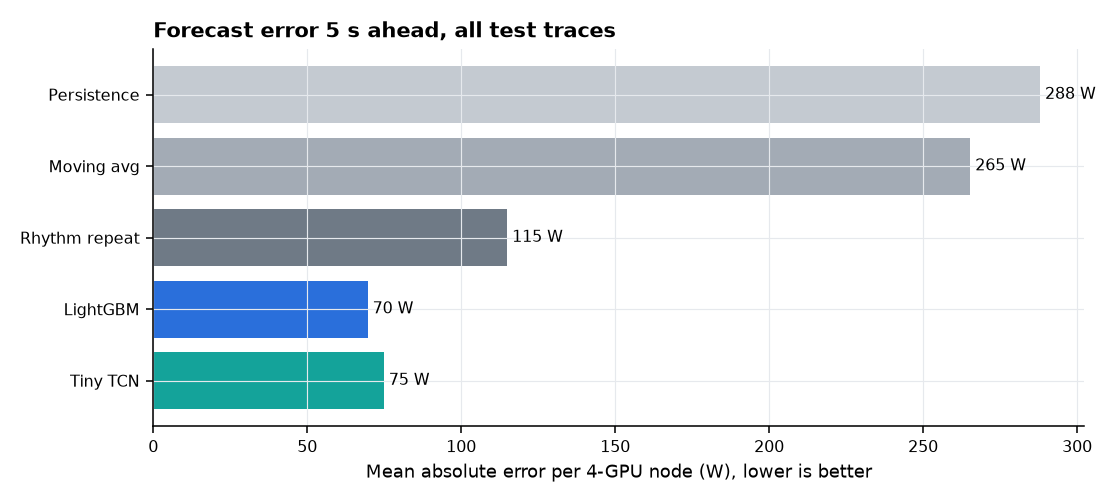

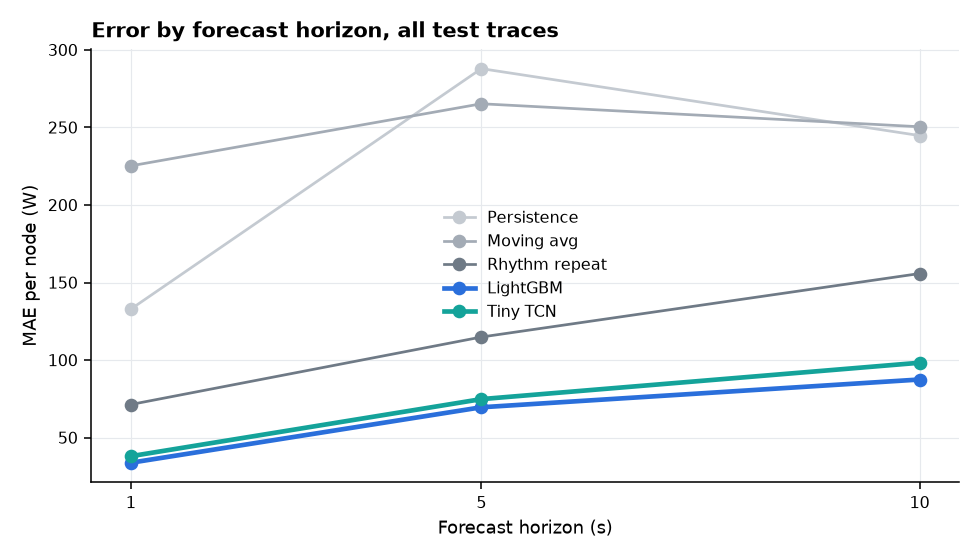

In [4]:
display(Image('reports/figures/model_comparison_5s.png'))
display(Image('reports/figures/error_by_horizon.png'))

## By workload (MAE, W per node)

In [5]:
fw = pd.read_csv('reports/tables/forecast_by_workload.csv')
fw[fw.horizon_s == 5].pivot(index='workload', columns='model', values='MAE').round(0)

model,lightgbm,moving_avg,persistence,rhythm,tcn
workload,,,,,
inference_offline,182.0,282.0,297.0,302.0,187.0
inference_online_finite,128.0,406.0,285.0,285.0,147.0
inference_online_rate,127.0,151.0,132.0,138.0,134.0
train_llama2_70b_lora,39.0,293.0,449.0,71.0,45.0
train_stable_diffusion,50.0,246.0,240.0,79.0,53.0


## Including zero-shot foundation models (stratified sample of test points)

horizon_s,1,5,10
model,,,
chronos_bolt_small,111.6,199.0,249.1
lightgbm,49.7,106.7,144.4
moving_avg,219.0,279.7,334.8
persistence,115.1,279.3,292.4
rhythm,96.8,168.4,256.7
tcn,59.8,114.3,159.1
timesfm_2p5,68.1,144.4,229.2


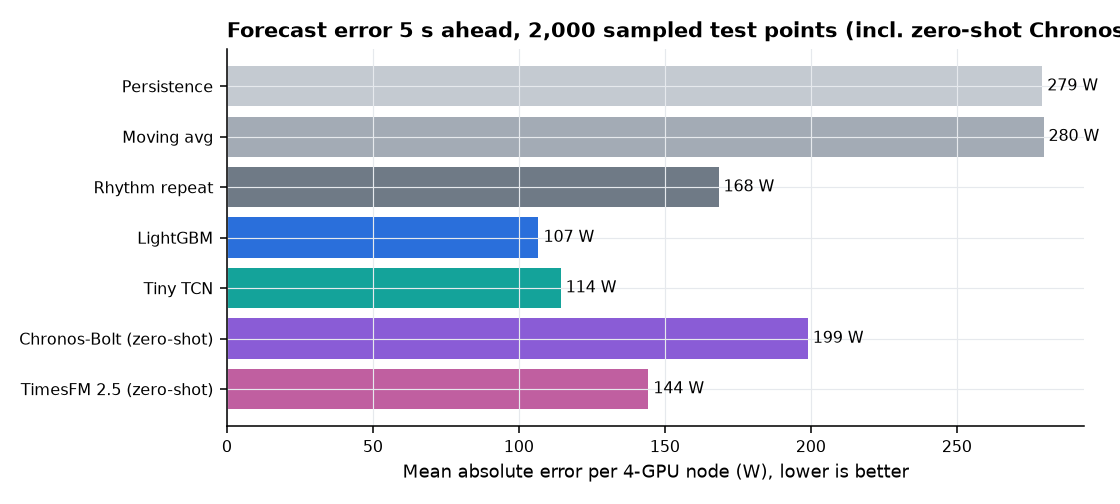

In [6]:
fs = pd.read_csv('reports/tables/forecast_subset_with_chronos.csv')
display(fs.pivot(index='model', columns='horizon_s', values='MAE').round(1))
display(Image('reports/figures/model_comparison_5s_with_chronos.png'))

## Drop warning (will a big drop start within 5 s?)

,model,threshold,events,recall_1s,mean_lead_s,alarm_episodes,episode_precision,false_alarms_per_hour,precision,recall,F1,AP
0,lightgbm,0.731,4280,0.824,4.866,3689,0.972,2.284,0.973,0.784,0.868,0.927
1,tcn,0.782,4280,0.824,4.860,3746,0.958,3.538,0.968,0.778,0.863,0.915
2,rhythm_alarm,0.002,4280,0.835,4.885,8938,0.399,120.343,0.200,0.797,0.320,0.542


,workload,threshold,events,recall_1s,mean_lead_s,alarm_episodes,episode_precision,false_alarms_per_hour,precision,recall,F1,AP
0,inference_offline,0.731,367,0.422,3.908,225,0.800,15.169,0.776,0.267,0.397,0.571
1,inference_online_finite,0.731,219,0.699,4.125,182,0.918,3.881,0.843,0.470,0.604,0.756
2,inference_online_rate,0.731,132,0.000,0.000,0,0.000,0.000,0.000,0.000,0.000,0.075
3,train_llama2_70b_lora,0.731,315,0.241,4.439,112,0.714,3.021,0.863,0.190,0.312,0.442
4,train_stable_diffusion,0.731,3247,0.968,4.960,3170,0.997,0.428,0.989,0.953,0.970,0.989


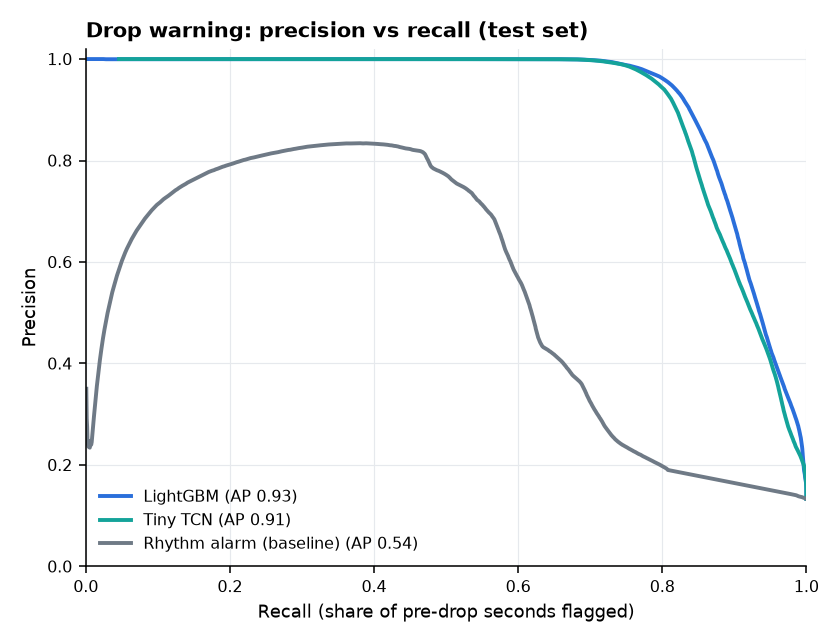

In [7]:
display(pd.read_csv('reports/tables/drop_warning.csv').round(3))
display(pd.read_csv('reports/tables/drop_warning_by_workload.csv').round(3))
display(Image('reports/figures/drop_warning_pr_curve.png'))

## Actual vs predicted on example windows

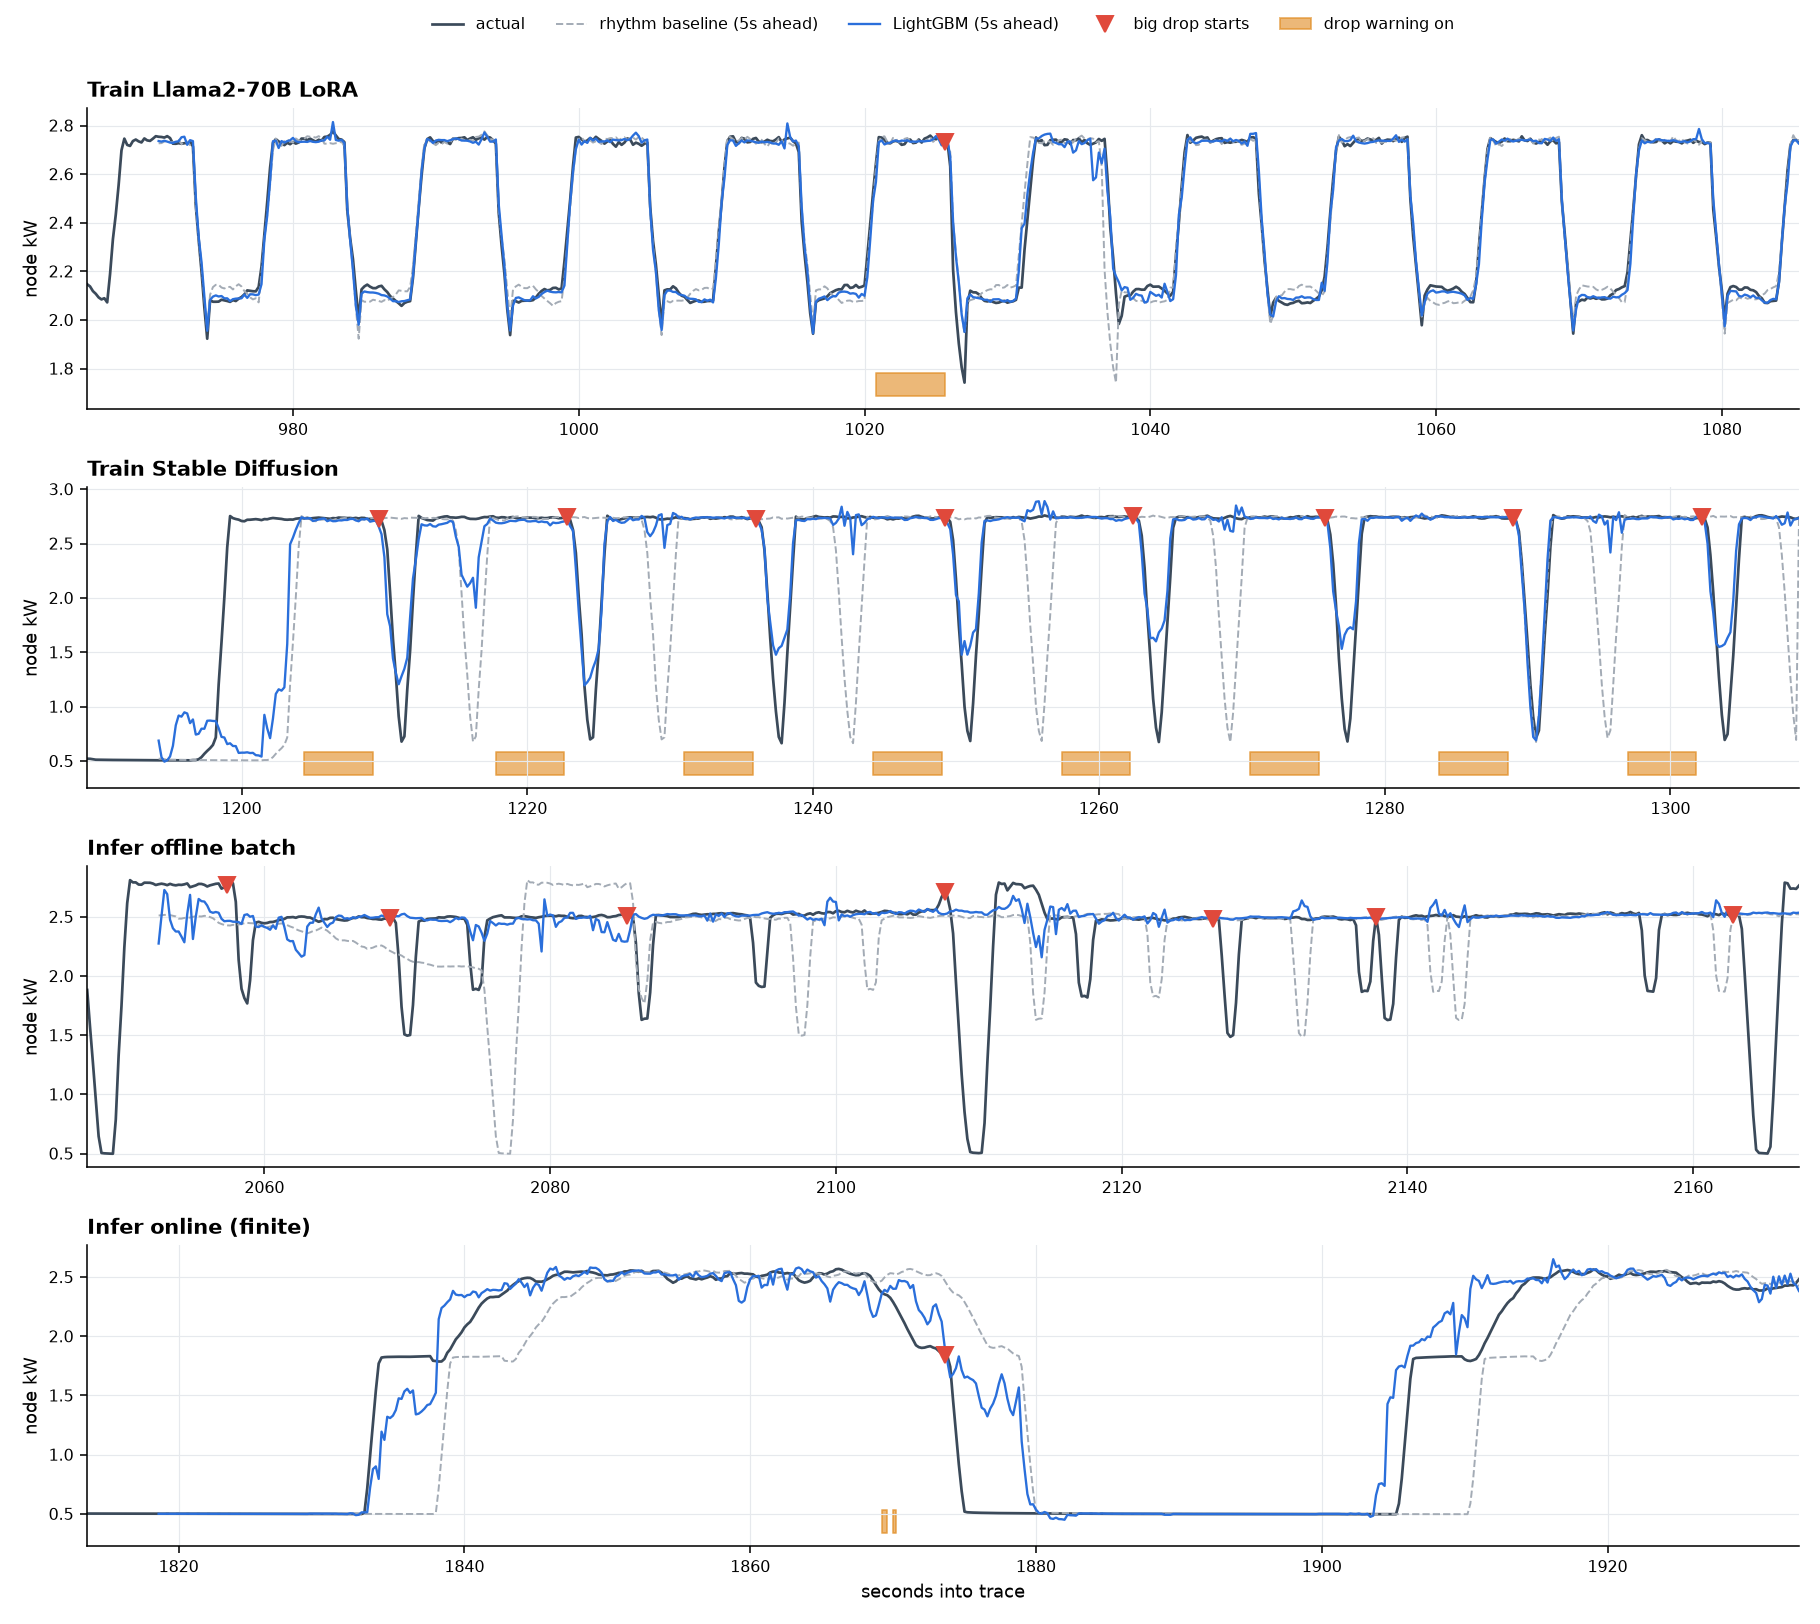

In [8]:
display(Image('reports/figures/forecast_overlays_5s.png'))

## Generalisation to unseen workload types (LightGBM retrained without that workload)

In [9]:
pd.read_csv('reports/tables/generalization_lowo.csv').round(2)

,held_out_workload,lgb_mae_1s,rhythm_mae_1s,persist_mae_1s,lgb_mae_5s,rhythm_mae_5s,persist_mae_5s,lgb_mae_10s,rhythm_mae_10s,persist_mae_10s,lgb_gain_vs_rhythm_5s_pct,drop_recall_1s,drop_mean_lead_s,false_alarms_per_hour,drop_AP,rhythm_alarm_AP
0,inference_offline,153.72,222.16,160.77,286.00,301.62,297.09,322.06,310.62,315.27,5.18,0.03,2.28,15.84,0.19,0.18
1,inference_online_finite,75.91,67.50,67.37,327.18,284.90,284.77,539.65,541.67,541.67,-14.84,0.00,0.00,0.00,0.12,0.08
2,inference_online_rate,82.74,89.27,90.14,150.14,138.31,131.97,237.10,200.22,198.01,-8.55,0.02,3.27,17.59,0.04,0.06
3,train_llama2_70b_lora,97.24,61.85,117.23,380.49,71.19,448.98,288.90,68.15,87.62,-434.51,0.59,3.54,346.67,0.07,0.12
4,train_stable_diffusion,195.16,54.27,154.38,210.22,79.03,240.13,252.25,104.75,265.71,-166.01,0.99,4.92,125.19,0.17,0.72


## Inference latency on CPU (single prediction, 1 thread)

In [10]:
pd.read_csv('reports/tables/latency.csv')

,model,ms_per_prediction
0,LightGBM (feature computation + 3 horizons + d...,10.34
1,rhythm / persistence / moving-avg baselines (f...,6.72
2,"tiny TCN (46,148 params, all 4 outputs)",1.18
3,"chronos-bolt-small (48M params, zero-shot)",19.35
4,"timesfm-2.5 (200M params, zero-shot)",190.74
